In [1]:
import lifetimes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os

df = pd.read_csv("lifetimes_summary_with_CLV.csv")
dfraw = pd.read_csv("group_assignment_2026.csv")
print(f"Loaded: {len(df):,} rows")
print(f"Columns: {df.columns.tolist()}")

Loaded: 875,558 rows
Columns: ['CustomerID', 'frequency', 'recency', 'T', 'monetary_value', 'pred_purchases_6m', 'CLV_6m', 'Channel', 'StoreName']


# Get the correct segmentation

In [2]:
# Correct segmentation — 75th percentile among REPEATERS only
repeaters = df[df['frequency'] > 0]
clv_75th = repeaters['CLV_6m'].quantile(0.75)
print(f"75th percentile CLV (repeaters only): €{clv_75th:.2f}")

# Assign segments
def assign_segment(row):
    if row['frequency'] == 0:
        return 'One-timer'
    elif row['CLV_6m'] >= clv_75th:
        return 'Star'
    else:
        return 'Casual'

df['segment'] = df.apply(assign_segment, axis=1)

# Count per segment
print("\nSegment breakdown:")
for seg in ['Star', 'Casual', 'One-timer']:
    count = (df['segment'] == seg).sum()
    pct = count / len(df) * 100
    print(f"  {seg}: {count:,} customers ({pct:.1f}%)")

75th percentile CLV (repeaters only): €34.87

Segment breakdown:
  Star: 81,571 customers (9.3%)
  Casual: 244,713 customers (27.9%)
  One-timer: 549,274 customers (62.7%)


In [3]:
# For each segment, calculate key retention metrics
# This gives you the numbers to back up your strategy

for segment in ['Star', 'Casual', 'One-timer']:

    # Filter to this segment
    seg_df = df[df['segment'] == segment]

    print(f"\n{'='*40}")
    print(f"SEGMENT: {segment} ({len(seg_df):,} customers)")
    print(f"{'='*40}")

    # Key metrics
    print(f"Avg predicted CLV (6m):  €{seg_df['CLV_6m'].mean():.2f}")
    print(f"Median CLV (6m):         €{seg_df['CLV_6m'].median():.2f}")
    print(f"Avg order frequency:     {seg_df['frequency'].mean():.1f} repeat orders")
    print(f"Avg monetary value:      €{seg_df['monetary_value'].mean():.2f}")
    print(f"Avg recency (days):      {seg_df['recency'].mean():.0f} days")
    print(f"Avg customer age (days): {seg_df['T'].mean():.0f} days")

    # Channel breakdown
    print(f"\nTop channels:")
    channel_counts = seg_df['Channel'].value_counts()
    for channel, count in channel_counts.items():
        pct = count / len(seg_df) * 100
        print(f"  {channel}: {count:,} ({pct:.1f}%)")


SEGMENT: Star (81,571 customers)
Avg predicted CLV (6m):  €78.21
Median CLV (6m):         €60.04
Avg order frequency:     6.6 repeat orders
Avg monetary value:      €46.77
Avg recency (days):      384 days
Avg customer age (days): 444 days

Top channels:
  TakeAway: 57,736 (70.8%)
  Website: 23,490 (28.8%)
  ConsumerApp: 226 (0.3%)
  UberEats: 85 (0.1%)
  Intake module: 34 (0.0%)

SEGMENT: Casual (244,713 customers)
Avg predicted CLV (6m):  €12.45
Median CLV (6m):         €10.19
Avg order frequency:     2.1 repeat orders
Avg monetary value:      €39.69
Avg recency (days):      224 days
Avg customer age (days): 511 days

Top channels:
  TakeAway: 174,804 (71.4%)
  Website: 57,369 (23.4%)
  ConsumerApp: 5,509 (2.3%)
  UberEats: 3,693 (1.5%)
  Intake module: 3,338 (1.4%)

SEGMENT: One-timer (549,274 customers)
Avg predicted CLV (6m):  €6.19
Median CLV (6m):         €4.13
Avg order frequency:     0.0 repeat orders
Avg monetary value:      €0.00
Avg recency (days):      0 days
Avg customer

In [4]:
# For Stars on TakeAway vs owned channels
# This shows the CLV difference between TakeAway Stars and Website Stars
# Which is your evidence for WHY channel migration matters

stars = df[df['segment'] == 'Star']
casuals = df[df['segment'] == 'Casual']

print("=== STAR segment: CLV by channel ===")
star_channel = stars.groupby('Channel')['CLV_6m'].agg(['mean', 'median', 'count'])
star_channel.columns = ['Avg CLV', 'Median CLV', 'Count']
star_channel = star_channel.sort_values('Avg CLV', ascending=False)
print(star_channel.round(2))

print("\n=== CASUAL segment: CLV by channel ===")
casual_channel = casuals.groupby('Channel')['CLV_6m'].agg(['mean', 'median', 'count'])
casual_channel.columns = ['Avg CLV', 'Median CLV', 'Count']
casual_channel = casual_channel.sort_values('Avg CLV', ascending=False)
print(casual_channel.round(2))

print("\n=== ONE-TIMER segment: channel breakdown ===")
onetimers = df[df['segment'] == 'One-timer']
ot_channel = onetimers['Channel'].value_counts()
ot_pct = onetimers['Channel'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': ot_channel, 'Pct': ot_pct.round(1)}))

=== STAR segment: CLV by channel ===
               Avg CLV  Median CLV  Count
Channel                                  
Website          80.11       61.51  23490
TakeAway         77.55       59.51  57736
ConsumerApp      63.76       54.04    226
UberEats         55.13       47.97     85
Intake module    54.39       49.50     34

=== CASUAL segment: CLV by channel ===
               Avg CLV  Median CLV   Count
Channel                                   
Website          13.36       11.34   57369
TakeAway         12.61       10.42  174804
ConsumerApp       7.23        5.85    5509
Intake module     5.34        4.19    3338
UberEats          5.18        3.99    3693

=== ONE-TIMER segment: channel breakdown ===
                      Count   Pct
Channel                          
TakeAway             376630  68.6
Website              142626  26.0
UberEats              13236   2.4
Intake module         13217   2.4
ConsumerApp            3559   0.6
S4D - Cash register       6   0.0


Test for significance between channels: Website vs Takeaway

In [5]:
from scipy import stats

# Filter Stars on Website vs TakeAway
stars = df[df['segment'] == 'Star']
website_stars = stars[stars['Channel'] == 'Website']['CLV_6m']
takeaway_stars = stars[stars['Channel'] == 'TakeAway']['CLV_6m']

# Mann-Whitney U test (non-parametric, good for skewed data)
stat, p_value = stats.mannwhitneyu(website_stars, takeaway_stars, alternative='two-sided')

print("=== Website vs TakeAway Stars: CLV difference ===")
print(f"Website Stars avg CLV:   €{website_stars.mean():.2f}")
print(f"TakeAway Stars avg CLV:  €{takeaway_stars.mean():.2f}")
print(f"Difference:              €{website_stars.mean() - takeaway_stars.mean():.2f}")
print(f"\nMann-Whitney U statistic: {stat:.0f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("\nConclusion: The difference IS statistically significant (p < 0.05)")
    print("Website Stars genuinely have higher CLV — not random chance")
else:
    print("\nConclusion: The difference is NOT statistically significant (p >= 0.05)")
    print("Cannot conclude Website Stars have higher CLV with confidence")

=== Website vs TakeAway Stars: CLV difference ===
Website Stars avg CLV:   €80.11
TakeAway Stars avg CLV:  €77.55
Difference:              €2.57

Mann-Whitney U statistic: 701403400
P-value: 0.0000

Conclusion: The difference IS statistically significant (p < 0.05)
Website Stars genuinely have higher CLV — not random chance


Calculate monetary value for the consumerapp and webiste for stars and casuals

In [6]:
# Calculate monetary value and order stats for Stars and Casuals
# on owned channels (Website + ConsumerApp) specifically

owned_channels = ['Website', 'ConsumerApp']

for segment in ['Star', 'Casual']:
    seg_df = df[df['segment'] == segment]
    owned_df = seg_df[seg_df['Channel'].isin(owned_channels)]

    print(f"\n{'='*45}")
    print(f"{segment.upper()} — Owned channels only")
    print(f"{'='*45}")
    print(f"Total customers: {len(owned_df):,}")
    print(f"Avg monetary value (per order): €{owned_df['monetary_value'].mean():.2f}")
    print(f"Median monetary value:          €{owned_df['monetary_value'].median():.2f}")
    print(f"Avg CLV 6m:                     €{owned_df['CLV_6m'].mean():.2f}")
    print(f"Avg frequency (repeat orders):  {owned_df['frequency'].mean():.1f}")

    # Distribution of monetary value
    print(f"\nMonetary value distribution:")
    print(f"  Bottom 25%: €{owned_df['monetary_value'].quantile(0.25):.2f}")
    print(f"  Median:     €{owned_df['monetary_value'].quantile(0.50):.2f}")
    print(f"  Top 25%:    €{owned_df['monetary_value'].quantile(0.75):.2f}")
    print(f"  Top 10%:    €{owned_df['monetary_value'].quantile(0.90):.2f}")

    # Channel breakdown within owned
    print(f"\nChannel split:")
    for ch in owned_channels:
        ch_df = owned_df[owned_df['Channel'] == ch]
        print(f"  {ch}: {len(ch_df):,} customers, avg order €{ch_df['monetary_value'].mean():.2f}")


STAR — Owned channels only
Total customers: 23,716
Avg monetary value (per order): €49.11
Median monetary value:          €44.15
Avg CLV 6m:                     €79.96
Avg frequency (repeat orders):  7.0

Monetary value distribution:
  Bottom 25%: €34.79
  Median:     €44.15
  Top 25%:    €57.08
  Top 10%:    €75.17

Channel split:
  Website: 23,490 customers, avg order €49.09
  ConsumerApp: 226 customers, avg order €51.12

CASUAL — Owned channels only
Total customers: 62,878
Avg monetary value (per order): €42.20
Median monetary value:          €39.25
Avg CLV 6m:                     €12.82
Avg frequency (repeat orders):  2.3

Monetary value distribution:
  Bottom 25%: €29.03
  Median:     €39.25
  Top 25%:    €49.50
  Top 10%:    €65.14

Channel split:
  Website: 57,369 customers, avg order €42.16
  ConsumerApp: 5,509 customers, avg order €42.58


Calculate the time between orders for Casuals and Stars

In [7]:
# Calculate average inter-order gap for Casuals
# Gap = customer age (T) / frequency
# This tells us how long on average between orders

casuals = df[df['segment'] == 'Casual']
stars = df[df['segment'] == 'Star']

# Only for owned channels
owned = ['Website', 'ConsumerApp']
casuals_owned = casuals[casuals['Channel'].isin(owned)]
stars_owned = stars[stars['Channel'].isin(owned)]

# Inter-purchase gap = T / frequency
# Only for customers with frequency > 0 to avoid division by zero
casuals_gap = casuals_owned[casuals_owned['frequency'] > 0].copy()
casuals_gap['avg_gap_days'] = casuals_gap['T'] / casuals_gap['frequency']

stars_gap = stars_owned[stars_owned['frequency'] > 0].copy()
stars_gap['avg_gap_days'] = stars_gap['T'] / stars_gap['frequency']

print("=== Average gap between orders ===")
print(f"Casuals (owned): {casuals_gap['avg_gap_days'].mean():.0f} days between orders")
print(f"Stars (owned):   {stars_gap['avg_gap_days'].mean():.0f} days between orders")
print(f"\nIf we reduce Casual gap to match Stars,")
print(f"frequency would increase from 2.3 to approximately {casuals_gap['T'].mean() / stars_gap['avg_gap_days'].mean():.1f} orders")

=== Average gap between orders ===
Casuals (owned): 341 days between orders
Stars (owned):   95 days between orders

If we reduce Casual gap to match Stars,
frequency would increase from 2.3 to approximately 5.6 orders


# **Evenness of order**

To support the point we made on difference in order habits of star customers and casual customers, we measured the evenness of order with standard deviation of time gaps between orders for each customer, of star and casual customers.

In [8]:
# How even is the time gap between orders for stars and casuals?

dfrawstars = dfraw[dfraw['CustomerID'].isin(stars['CustomerID'])]
dfrawstars["DeliveryTimestamp"] = pd.to_datetime(dfrawstars["DeliveryTimestamp"], utc=True, errors="coerce")


dfrawstars = dfrawstars.sort_values(['CustomerID', 'DeliveryTimestamp'])
dfrawstars['timediff'] = dfrawstars.groupby('CustomerID')['DeliveryTimestamp'].diff()

dfrawstars['days_diff'] = dfrawstars['timediff'].dt.days
dfrawstars['days_diff'] = dfrawstars['days_diff'].fillna(0).astype(int)

dfstarsdiffsum = dfrawstars.groupby("CustomerID")['days_diff'].agg(['mean', 'std'])

In [9]:
dfrawC = dfraw[dfraw['CustomerID'].isin(casuals['CustomerID'])]
dfrawC["DeliveryTimestamp"] = pd.to_datetime(dfrawC["DeliveryTimestamp"], utc=True, errors="coerce")


dfrawC = dfrawC.sort_values(['CustomerID', 'DeliveryTimestamp'])
dfrawC['timediff'] = dfrawC.groupby('CustomerID')['DeliveryTimestamp'].diff()

dfrawC['days_diff'] = dfrawC['timediff'].dt.days
dfrawC['days_diff'] = dfrawC['days_diff'].fillna(0).astype(int)

dfCdiffsum = dfrawC.groupby("CustomerID")['days_diff'].agg(['mean', 'std'])

0.25    31.913418
0.50    52.706736
0.75    80.801024
Name: std, dtype: float64


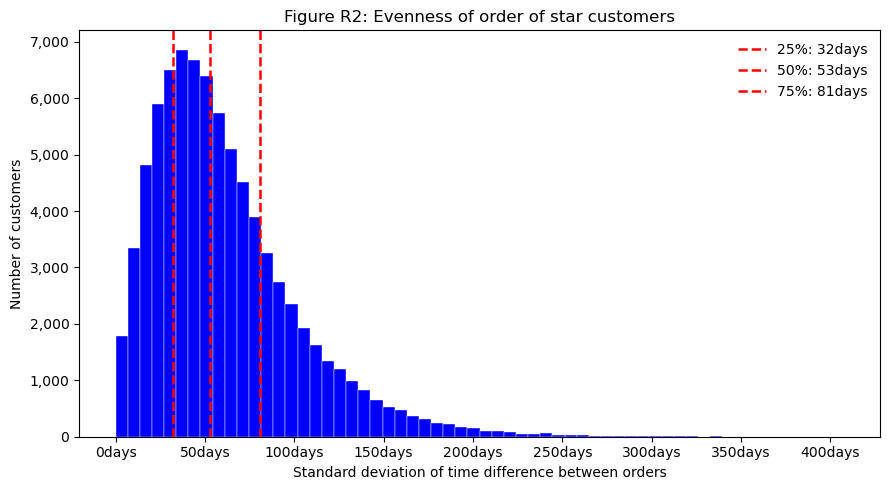

In [10]:
stdstars      = dfstarsdiffsum['std']
q1 = dfstarsdiffsum['std'].quantile(0.25)
q2 = dfstarsdiffsum['std'].quantile(0.5)
q3 = dfstarsdiffsum['std'].quantile(0.75)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(stdstars, bins=60, color="blue", edgecolor="white", linewidth=0.3)
ax.axvline(q1, color="red", linewidth=1.8, linestyle="--", label=f"25%: {q1:.0f}days")
ax.axvline(q2, color="red", linewidth=1.8, linestyle="--", label=f"50%: {q2:.0f}days")
ax.axvline(q3, color="red", linewidth=1.8, linestyle="--", label=f"75%: {q3:.0f}days")
ax.set_xlabel("Standard deviation of time difference between orders")
ax.set_ylabel("Number of customers")
ax.set_title("Figure R2: Evenness of order of star customers")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}days"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend(frameon=False)
fig.tight_layout()
plt.savefig("figure_R2.png")


quantiles1 = dfstarsdiffsum['std'].quantile([0.25, 0.5, 0.75])
print(quantiles1)


0.25     33.941125
0.50     76.309895
0.75    143.542677
Name: std, dtype: float64


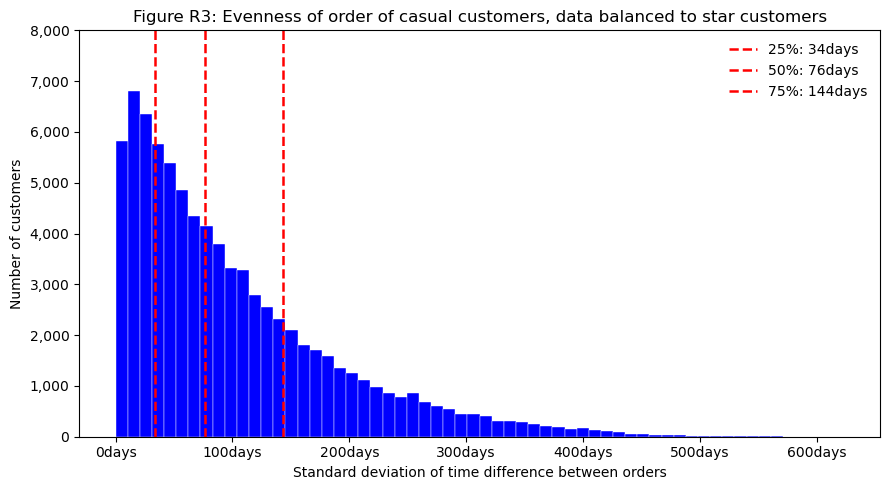

In [12]:
dfCdiffsum_ds = dfCdiffsum.sample(n=len(dfstarsdiffsum), random_state=42)

stdC      = dfCdiffsum_ds['std']
q1 = dfCdiffsum_ds['std'].quantile(0.25)
q2 = dfCdiffsum_ds['std'].quantile(0.5)
q3 = dfCdiffsum_ds['std'].quantile(0.75)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(stdC, bins=60, color="blue", edgecolor="white", linewidth=0.3)
ax.axvline(q1, color="red", linewidth=1.8, linestyle="--", label=f"25%: {q1:.0f}days")
ax.axvline(q2, color="red", linewidth=1.8, linestyle="--", label=f"50%: {q2:.0f}days")
ax.axvline(q3, color="red", linewidth=1.8, linestyle="--", label=f"75%: {q3:.0f}days")
ax.set_xlabel("Standard deviation of time difference between orders")
ax.set_ylabel("Number of customers")
plt.ylim(0, 8000)
ax.set_title("Figure R3: Evenness of order of casual customers, data balanced to star customers")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}days"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend(frameon=False)
fig.tight_layout()
plt.savefig("figure_R3.png")

quantiles2 = dfCdiffsum_ds['std'].quantile([0.25, 0.5, 0.75])
print(quantiles2)

According to the results, star customers order more evenly than casual customers, as more of their standard deviations of ordering time gap are small. This stability also contributes to the high CLV of the star customers.

See the gap between order for different channels


In [13]:
# Average inter-order gap per channel for Casuals and Stars
# This shows where the gap problem is most severe

print("=== Casual: avg gap between orders by channel ===")
for channel in ['Website', 'ConsumerApp', 'TakeAway']:
    ch_df = casuals[casuals['Channel'] == channel]
    ch_df = ch_df[ch_df['frequency'] > 0].copy()
    ch_df['avg_gap_days'] = ch_df['T'] / ch_df['frequency']
    print(f"  {channel}: {ch_df['avg_gap_days'].mean():.0f} days "
          f"({len(ch_df):,} customers)")

print("\n=== Star: avg gap between orders by channel ===")
for channel in ['Website', 'ConsumerApp', 'TakeAway']:
    ch_df = stars[stars['Channel'] == channel]
    ch_df = ch_df[ch_df['frequency'] > 0].copy()
    ch_df['avg_gap_days'] = ch_df['T'] / ch_df['frequency']
    print(f"  {channel}: {ch_df['avg_gap_days'].mean():.0f} days "
          f"({len(ch_df):,} customers)")

print("\n=== What happens if we reduce each Casual channel gap by 30%? ===")
print("(Simulating impact of urgency tactic on frequency)")
for channel in ['Website', 'ConsumerApp', 'TakeAway']:
    ch_df = casuals[casuals['Channel'] == channel]
    ch_df = ch_df[ch_df['frequency'] > 0].copy()
    ch_df['avg_gap_days'] = ch_df['T'] / ch_df['frequency']
    current_gap = ch_df['avg_gap_days'].mean()
    current_freq = ch_df['frequency'].mean()
    new_gap = current_gap * 0.70  # 30% reduction
    new_freq = ch_df['T'].mean() / new_gap
    print(f"  {channel}: gap {current_gap:.0f} → {new_gap:.0f} days, "
          f"frequency {current_freq:.1f} → {new_freq:.1f} orders")

=== Casual: avg gap between orders by channel ===
  Website: 342 days (57,369 customers)
  ConsumerApp: 331 days (5,509 customers)
  TakeAway: 345 days (174,804 customers)

=== Star: avg gap between orders by channel ===
  Website: 94 days (23,490 customers)
  ConsumerApp: 113 days (226 customers)
  TakeAway: 87 days (57,736 customers)

=== What happens if we reduce each Casual channel gap by 30%? ===
(Simulating impact of urgency tactic on frequency)
  Website: gap 342 → 240 days, frequency 2.2 → 2.2 orders
  ConsumerApp: gap 331 → 231 days, frequency 3.2 → 2.5 orders
  TakeAway: gap 345 → 242 days, frequency 2.1 → 2.1 orders


Finding right moment to send push notification for casuals in owned channel

In [14]:
# What is the recency distribution for Casuals on owned channels?
# This tells us when to trigger the personalised re-engagement

casuals_owned = casuals[casuals['Channel'].isin(['Website', 'ConsumerApp'])]

print("=== Casual owned-channel recency distribution ===")
print("(Days between first and last order)")
print(f"  25th percentile: {casuals_owned['recency'].quantile(0.25):.0f} days")
print(f"  Median:          {casuals_owned['recency'].quantile(0.50):.0f} days")
print(f"  75th percentile: {casuals_owned['recency'].quantile(0.75):.0f} days")
print(f"  Avg:             {casuals_owned['recency'].mean():.0f} days")

# Also calculate: what % of Casuals have recency = 0?
# These are customers whose first and last order are the same
# meaning they ordered more than once but all on the same day
zero_recency = (casuals_owned['recency'] == 0).sum()
zero_pct = zero_recency / len(casuals_owned) * 100
print(f"\n  Customers with recency = 0: {zero_recency:,} ({zero_pct:.1f}%)")
print(f"  (These ordered multiple times but all clustering around same period)")

=== Casual owned-channel recency distribution ===
(Days between first and last order)
  25th percentile: 96 days
  Median:          208 days
  75th percentile: 356 days
  Avg:             240 days

  Customers with recency = 0: 0 (0.0%)
  (These ordered multiple times but all clustering around same period)


Opportunity of converting one-timers

In [15]:
# One-timer analysis
# What channels do they come from and what's their predicted CLV?

onetimers = df[df['segment'] == 'One-timer']

print("=== ONE-TIMER segment overview ===")
print(f"Total: {len(onetimers):,} customers ({len(onetimers)/len(df)*100:.1f}%)")
print(f"Avg predicted CLV_6m: €{onetimers['CLV_6m'].mean():.2f}")
print(f"Median CLV_6m:        €{onetimers['CLV_6m'].median():.2f}")

print("\n=== Channel breakdown ===")
for channel in onetimers['Channel'].value_counts().index:
    ch_df = onetimers[onetimers['Channel'] == channel]
    print(f"  {channel}: {len(ch_df):,} ({len(ch_df)/len(onetimers)*100:.1f}%)")

print("\n=== Owned channel one-timers (reachable) ===")
owned_ot = onetimers[onetimers['Channel'].isin(['Website', 'ConsumerApp'])]
print(f"  Total reachable: {len(owned_ot):,} ({len(owned_ot)/len(onetimers)*100:.1f}%)")
print(f"  Avg CLV_6m: €{owned_ot['CLV_6m'].mean():.2f}")
print(f"  Avg T (days since first order): {owned_ot['T'].mean():.0f} days")

print("\n=== Revenue at stake ===")
total_ot_clv = onetimers['CLV_6m'].sum()
owned_ot_clv = owned_ot['CLV_6m'].sum()
print(f"  Total predicted CLV of all one-timers: €{total_ot_clv:,.0f}")
print(f"  Owned channel one-timers CLV: €{owned_ot_clv:,.0f}")
print(f"  If we convert 10% of owned one-timers to Casuals,")
print(f"  potential CLV gain: €{owned_ot_clv * 0.10 * (128.02/57.17):,.0f}")

=== ONE-TIMER segment overview ===
Total: 549,274 customers (62.7%)
Avg predicted CLV_6m: €6.19
Median CLV_6m:        €4.13

=== Channel breakdown ===
  TakeAway: 376,630 (68.6%)
  Website: 142,626 (26.0%)
  UberEats: 13,236 (2.4%)
  Intake module: 13,217 (2.4%)
  ConsumerApp: 3,559 (0.6%)
  S4D - Cash register: 6 (0.0%)

=== Owned channel one-timers (reachable) ===
  Total reachable: 146,185 (26.6%)
  Avg CLV_6m: €6.12
  Avg T (days since first order): 382 days

=== Revenue at stake ===
  Total predicted CLV of all one-timers: €3,400,085
  Owned channel one-timers CLV: €893,950
  If we convert 10% of owned one-timers to Casuals,
  potential CLV gain: €200,181


The average time between orders for Casuals

In [16]:
# Calculate average time between orders for Casuals
# We already have T (days since first order) and frequency (repeat orders)
# Inter-purchase gap = T / frequency
# This tells us the average number of days between orders

casuals_owned = df[
    (df['segment'] == 'Casual') &
    (df['Channel'].isin(['Website', 'ConsumerApp']))
]

# Only customers with frequency > 0 (all casuals should have this)
casuals_gap = casuals_owned[casuals_owned['frequency'] > 0].copy()
casuals_gap['avg_gap_days'] = casuals_gap['T'] / casuals_gap['frequency']

print("=== Average time between orders — Casuals (owned channels) ===")
print(f"Mean gap:          {casuals_gap['avg_gap_days'].mean():.0f} days")
print(f"Median gap:        {casuals_gap['avg_gap_days'].median():.0f} days")
print(f"25th percentile:   {casuals_gap['avg_gap_days'].quantile(0.25):.0f} days")
print(f"75th percentile:   {casuals_gap['avg_gap_days'].quantile(0.75):.0f} days")

print("\n=== What does a 30-day notification window mean? ===")
# What % of casuals have a gap SHORTER than 30 days?
# These are already ordering frequently enough — notification may not be needed
pct_under_30 = (casuals_gap['avg_gap_days'] < 30).mean() * 100
pct_30_to_90 = ((casuals_gap['avg_gap_days'] >= 30) &
                (casuals_gap['avg_gap_days'] < 90)).mean() * 100
pct_over_90 = (casuals_gap['avg_gap_days'] >= 90).mean() * 100

print(f"Casuals ordering more often than every 30 days:  {pct_under_30:.1f}%")
print(f"Casuals ordering every 30-90 days:               {pct_30_to_90:.1f}%")
print(f"Casuals ordering less often than every 90 days:  {pct_over_90:.1f}%")

print("\n=== All segments: avg gap comparison ===")
for seg in ['Star', 'Casual', 'One-timer']:
    seg_df = df[
        (df['segment'] == seg) &
        (df['Channel'].isin(['Website', 'ConsumerApp'])) &
        (df['frequency'] > 0)
    ].copy()
    seg_df['avg_gap_days'] = seg_df['T'] / seg_df['frequency']
    print(f"{seg}: {seg_df['avg_gap_days'].mean():.0f} days avg between orders")

=== Average time between orders — Casuals (owned channels) ===
Mean gap:          341 days
Median gap:        296 days
25th percentile:   186 days
75th percentile:   499 days

=== What does a 30-day notification window mean? ===
Casuals ordering more often than every 30 days:  0.3%
Casuals ordering every 30-90 days:               4.5%
Casuals ordering less often than every 90 days:  95.2%

=== All segments: avg gap comparison ===
Star: 95 days avg between orders
Casual: 341 days avg between orders
One-timer: nan days avg between orders
